In [2]:
import pandas as pd
import datetime
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import numpy as np
import scipy
import plotly.express as px
import requests
import io
import streamlit as st

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_rows', 1000) # Display more row of your dataframe
pd.options.display.float_format = '{:,}'.format # Separate number with comma


In [15]:
BASE_couverture_ciblée = "https://data.corsica/data-fair/api/v1/datasets/dispositif-de-couverture-ciblee-en-corse-points-dinteret/"

df = pd.read_csv(f"{BASE_couverture_ciblée}/lines?format=csv")
colonnes =[]
for col in df.columns:
    colonnes.append(col)

colonnes
params = {
    "format": "csv",
    "select": ",".join(colonnes),
    "size": 10000,   # maximum par page
}

In [17]:
url = f"{BASE_couverture_ciblée}/lines"
params = {
    "format": "json",
    "select": ",".join(colonnes),
    "size": 10000,   # maximum par page
}
lignes=[]

while url:
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    data = r.json()
    lignes.extend(data["results"])
    url = data.get("next")
    params = None   # l'URL "next" contient déjà les paramètres

df = pd.DataFrame(lignes)

colonnes_a_supprimer = [
    "20801",
    "20810",
    "20815",
    "20820",
    "id_point",
    "nb_sites_dossier",
    "origine_zone",
    "origine_coordonnées",
    "num_zone_arrete",
    "nom_point_arrete",
    "lien_arrete",
    "_i",
    "_rand",
    "_score",
    "_id",
    "numero_site_physique",
    "_identifiant_site",
]

df = df.drop(columns=colonnes_a_supprimer, errors="ignore")
df.to_csv("csv/couverture_reseau.csv", index=False)

## 3) Data visualisation de la couverture réseau

Cette section reprend la méthode du notebook des soldats : préparation de tableaux de synthèse, indicateurs principaux et tableau de bord en quatre graphiques.

In [5]:
from pathlib import Path

DATA_PATH = Path("csv/couverture_reseau.csv")
viz = pd.read_csv(DATA_PATH)

for column in ["departement", "nom_commune", "trimestre", "origine_coordonnees"]:
    viz[column] = viz[column].fillna("Non renseigné").astype(str).str.strip()

communes_renseignees = viz.loc[viz["nom_commune"] != "Non renseigné", "nom_commune"]
resume_departements = (
    viz["departement"]
    .value_counts()
    .rename_axis("departement")
    .reset_index(name="points")
)
resume_communes = (
    communes_renseignees
    .value_counts()
    .head(15)
    .sort_values()
    .rename_axis("commune")
    .reset_index(name="points")
)
resume_origines = (
    viz["origine_coordonnees"]
    .value_counts()
    .rename_axis("origine")
    .reset_index(name="points")
)

ordre_trimestres = sorted(
    viz["trimestre"].unique(),
    key=lambda value: (
        int(value[:4]) if value[:4].isdigit() else 0,
        int(value[-1]) if value[-1].isdigit() else 0,
    ),
)
par_trimestre = (
    viz["trimestre"]
    .value_counts()
    .reindex(ordre_trimestres, fill_value=0)
    .rename_axis("trimestre")
    .reset_index(name="points")
)

synthese = pd.DataFrame(
    {
        "Indicateur": [
            "Nombre total de points",
            "Nombre de communes renseignées",
            "Département le plus représenté",
            "Trimestre le plus représenté",
            "Origine de coordonnées principale",
        ],
        "Valeur": [
            f"{len(viz):,}",
            communes_renseignees.nunique(),
            resume_departements.iloc[0]["departement"],
            par_trimestre.loc[par_trimestre["points"].idxmax(), "trimestre"],
            resume_origines.iloc[0]["origine"],
        ],
    }
)

print(f"Nombre de points : {len(viz):,}")
print(f"Communes renseignées : {len(communes_renseignees):,}")
synthese

Nombre de points : 6,036
Communes renseignées : 5,727


,Indicateur,Valeur
0,Nombre total de points,"6,036"
1,Nombre de communes renseignées,127
2,Département le plus représenté,HAUTE-CORSE
3,Trimestre le plus représenté,2026-T1
4,Origine de coordonnées principale,arrete


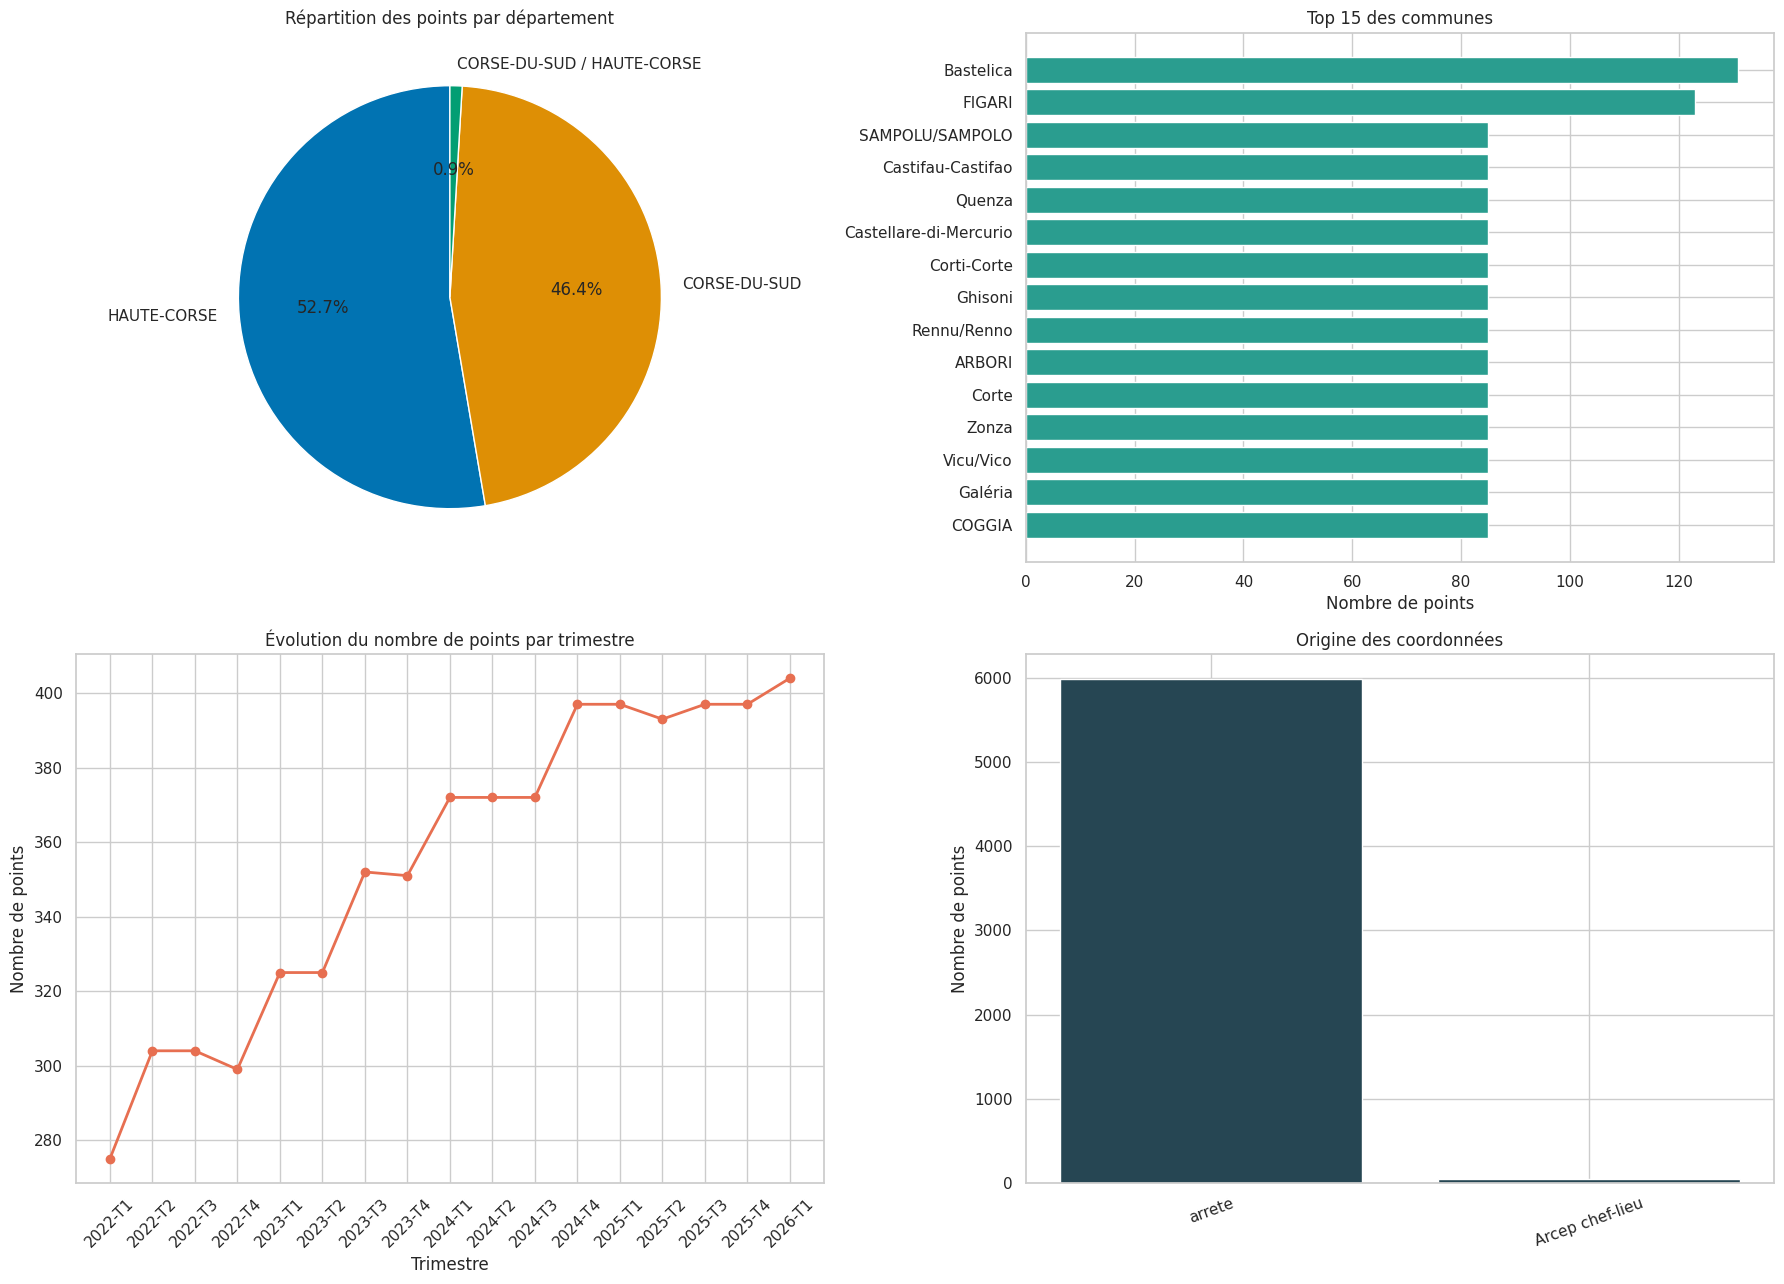

In [6]:
# Tableau de bord principal : départements, communes, trimestres et origine des coordonnées
sns.set_theme(style="whitegrid", palette="colorblind")
fig, axes = plt.subplots(2, 2, figsize=(18, 13))

# 1. Répartition des points par département
axes[0, 0].pie(
    resume_departements["points"],
    labels=resume_departements["departement"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"linewidth": 1, "edgecolor": "white"},
)
axes[0, 0].set_title("Répartition des points par département")

# 2. Communes avec le plus de points
axes[0, 1].barh(resume_communes["commune"], resume_communes["points"], color="#2a9d8f")
axes[0, 1].set_title("Top 15 des communes")
axes[0, 1].set_xlabel("Nombre de points")
axes[0, 1].set_ylabel("")

# 3. Évolution du nombre de points par trimestre
axes[1, 0].plot(
    par_trimestre["trimestre"],
    par_trimestre["points"],
    marker="o",
    linewidth=2,
    color="#e76f51",
)
axes[1, 0].set_title("Évolution du nombre de points par trimestre")
axes[1, 0].set_xlabel("Trimestre")
axes[1, 0].set_ylabel("Nombre de points")
axes[1, 0].tick_params(axis="x", rotation=45)

# 4. Répartition selon l'origine des coordonnées
axes[1, 1].bar(
    resume_origines["origine"],
    resume_origines["points"],
    color="#264653",
)
axes[1, 1].set_title("Origine des coordonnées")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Nombre de points")
axes[1, 1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()